In [ ]:
print("hello") #updated test

hello


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#since we don't need to extract

!cp "/content/drive/MyDrive/Kennydataset_IQ_v2_8192.h5" /content/

'''
# getting data
!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/
!unzip -q /content/RadioMLDataset2018.zip -d /content/data/
'''

Mounted at /content/drive


'\n# getting data\n!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/\n!unzip -q /content/RadioMLDataset2018.zip -d /content/data/\n'

In [ ]:
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # basically only using gpu when available
print(f"using device - {device}")

from torch.amp import autocast, GradScaler
scaler = GradScaler(device = 'cuda')


using device - cuda


In [ ]:
import os

save_dir = "/content/drive/MyDrive/RadioML_Models"
os.makedirs(save_dir, exist_ok=True)

model_save_path = os.path.join(save_dir, "RawIQ8192.pth")

# get rid previous checkpoint so training starts fresh if needed
if os.path.exists(model_save_path):
    os.remove(model_save_path)
    print("Removed old checkpoint. Starting fresh training.")

In [ ]:
print(os.cpu_count())

12


In [ ]:
#!df -h /dev/shm

### Loading the HDF5 Dataset

The dataset is stored in an HDF5 file, which is a common format for storing large amounts of numerical data. We'll use the `h5py` library to open this file and load the IQ samples (X), one-hot encoded class labels (Y), and Signal-to-Noise Ratio (SNR) values (Z).

In [ ]:
file_path = "/content/drive/MyDrive/Kennydataset_IQ_v2_8192.h5"

hdf5_file = h5py.File(file_path, 'r')

X = hdf5_file["X_iq"] # - IQ samples
Y = hdf5_file["Y"] # - one hot class labels
Z = hdf5_file["Z"] # - SNR values

In [ ]:

print("Datasets:")
for key in hdf5_file.keys():
    obj = hdf5_file[key]
    if isinstance(obj, h5py.Dataset):
        size_gb = obj.size * obj.dtype.itemsize / 1e9
        print(f"  {key:15s} shape {obj.shape}   dtype {obj.dtype}   ({size_gb:.2f} GB if fully loaded)")

print("\nAttributes:")
for k, v in hdf5_file.attrs.items():
    print(f"  {k}: {v}")


Datasets:
  X_iq            shape (346112, 8192, 2)   dtype float32   (22.68 GB if fully loaded)
  Y               shape (346112, 13)   dtype float32   (0.02 GB if fully loaded)
  Z               shape (346112, 1)   dtype float32   (0.00 GB if fully loaded)
  imp             shape (346112, 4)   dtype float32   (0.01 GB if fully loaded)

Attributes:
  N_frames_per_snr: [1024]
  N_samples: [8192]
  N_snr_levels: [26]
  N_total: [346112]
  SNR_definition: awgn measured over the full fs band (in-band SNR is higher for narrow signals)
  SNR_max: [30.]
  SNR_min: [-20.]
  USE_CFO: [1]
  USE_FADING: [1]
  USE_PARALLEL: [1]
  USE_PHASE_OFFSET: [1]
  USE_RS_VAR: [1]
  USE_TIMING_OFFSET: [1]
  complete: [1]
  created: 30-Sep-2026 13:53:13
  deflate_level: [4]
  frame_ms: [40.96]
  fs_hz: [200000.]
  fsk2_sep_hz: [25000.]
  fsk4_sep_hz: [6250.]
  generator: datasetGenerationIQ_Final_8192Frames.m
  gfsk_BT: [0.3]
  gfsk_pulse_length: [4]
  imp_rows: cfo_hz,Rs_scale,timing_offset_samples,k_factor
 

In [ ]:
print(f"X shape: {X.shape}")   # signals
print(f"Y shape: {Y.shape}")   # labels
print(f"Z shape: {Z.shape}")   # SNR
print(f"SNR range: {np.unique(Z)}")
print(f"Number of classes: {Y.shape[1]}")

X shape: (346112, 8192, 2)
Y shape: (346112, 13)
Z shape: (346112, 1)
SNR range: [-20. -18. -16. -14. -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.
   8.  10.  12.  14.  16.  18.  20.  22.  24.  26.  28.  30.]
Number of classes: 13


In [ ]:
# X into memory
print("Loading X into memory")
X_loaded = hdf5_file["X_iq"][:].astype(np.float32).transpose(0, 2, 1)
print(f" X shape: {X_loaded.shape}")

Loading X into memory
 X shape: (346112, 2, 8192)


In [ ]:
MOD_LABELS = [
    "BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "PAM4", "GFSK",
    "CPFSK", "2FSK", "4FSK", "B-FM", "AM-DSB", "AM-SSB"
]

labels = np.argmax(Y[:], axis = 1)
snrs = Z[:, 0].astype(int)

# rand seed yeeehawww
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"Total samples - {len(labels):,}")
print(f"Classes       - {len(MOD_LABELS)}")
print(f"SNR levels    - {sorted(np.unique(snrs).tolist())}")

Total samples - 346,112
Classes       - 13
SNR levels    - [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


In [ ]:
print("Unique label idx:", np.unique(labels))
print("Num unique labels:", len(np.unique(labels)))

for i, mod in enumerate(MOD_LABELS):
    print(f"{i:2d}: {mod}")

Unique label idx: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Num unique labels: 13
 0: BPSK
 1: QPSK
 2: 8PSK
 3: 16QAM
 4: 64QAM
 5: PAM4
 6: GFSK
 7: CPFSK
 8: 2FSK
 9: 4FSK
10: B-FM
11: AM-DSB
12: AM-SSB


In [ ]:
# Cell 4 - Dataset Class (index-based, no copying)

class RadioMLDataset(Dataset):
    def __init__(self, X_data, labels, snrs, indices, global_mean, global_std):
        self.X = X_data          # reference only - X_loaded stays in RAM once
        self.labels = labels[indices]
        self.snrs = snrs[indices]
        self.indices = indices
        self.global_mean = global_mean
        self.global_std = global_std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        raw = self.X[self.indices[idx]]

        # trying standardisation
        raw = (raw - self.global_mean) / (self.global_std + 1e-6)

        sample = torch.from_numpy(raw.copy())
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        snr = self.snrs[idx]
        return sample, label, snr

In [ ]:
# trying filtering for snr first - ttraining on the higher so the model isn't completely trash
from sklearn.model_selection import train_test_split

# Keep only samples above the SNR threshold
snr_threshold = -20
valid_indices = np.where(snrs >= snr_threshold)[0]

print(f"Using {len(valid_indices):,} samples with SNR >= {snr_threshold} dB")

BATCH_SIZE = 1024

# splitting for both modulation and snr

stratify_labels = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in valid_indices
])

train_idx, temp_idx = train_test_split(
    valid_indices,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=stratify_labels
)

temp_strat = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in temp_idx
])

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temp_strat
)

train_samples = X_loaded[train_idx]
global_mean = train_samples.mean()
global_std  = train_samples.std()
print(f"global_mean={global_mean:.6f}  global_std={global_std:.6f}")

train_data = RadioMLDataset(X_loaded, labels, snrs, train_idx, global_mean, global_std)
val_data = RadioMLDataset(X_loaded, labels, snrs, val_idx, global_mean, global_std)
test_data = RadioMLDataset(X_loaded, labels, snrs, test_idx, global_mean, global_std)


# Creating data loaders to handle the batching, and multiprocessing and stuff due to large dataset
# when you try dataloader - try with pin memrory true to speed up transfer or something
train_loader = DataLoader(train_data, batch_size = BATCH_SIZE, shuffle = True, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)
val_loader = DataLoader(val_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)
test_loader = DataLoader(test_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)

print(f"Train samples : {len(train_data):,}")
print(f"Val samples   : {len(val_data):,}")
print(f"Test samples  : {len(test_data):,}")

Using 346,112 samples with SNR >= -20 dB
global_mean=0.000116  global_std=2.389615
Train samples : 242,278
Val samples   : 51,917
Test samples  : 51,917


In [ ]:
print(np.min(snrs[train_idx]), np.max(snrs[train_idx]))

-20 30


In [ ]:
# write here and pretend you know what you're doing

class ResBlock(nn.Module):
  def __init__(self, channels, kernel_size = 3):
    super(ResBlock, self).__init__()
    self.conv1 = nn.Conv1d(channels, channels, kernel_size = kernel_size, padding = kernel_size//2)
    self.bn1 = nn.BatchNorm1d(channels)
    self.conv2 = nn.Conv1d(channels, channels, kernel_size = kernel_size, padding = kernel_size//2)
    self.bn2 = nn.BatchNorm1d(channels)
    self.relu = nn.ReLU()

  def forward(self, x):
    residual = x
    out = self.relu(self.bn1(self.conv1(x)))
    out = self.bn2(self.conv2(out))
    return self.relu(out + residual)

class CNNModel(nn.Module):
    def __init__(self, num_classes = 13):
        super(CNNModel, self).__init__()

        ## ADDING EXPANSAION OF CHANNELS WITH STEM
        self.stem = nn.Sequential(
            nn.Conv1d(2, 64, kernel_size = 7, padding = 3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
        )

        # residual stages
        self.stage1 = nn.Sequential(ResBlock(64), ResBlock(64), nn.MaxPool1d(2))
        self.stage2 = nn.Sequential(nn.Conv1d(64, 128, 1), ResBlock(128), ResBlock(128), nn.MaxPool1d(2))
        self.stage3 = nn.Sequential(nn.Conv1d(128, 256, 1), ResBlock(256), ResBlock(256), nn.MaxPool1d(2))
        self.stage4 = nn.MaxPool1d(2)

        self.pool = nn.AdaptiveAvgPool1d(4) #basically keeping the temporal structure. It is 4 time steps this way.


        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024, 256), #basically 256*4
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

In [ ]:
# you can tru and check the forward pass before moving onto the next bit
NUM_CLASSES = 13

model = CNNModel(num_classes=NUM_CLASSES).to(device)

# Grab one batch and run it through
sample_batch, sample_labels, sample_snrs = next(iter(train_loader))
sample_batch = sample_batch.to(device)

with torch.no_grad():
    output = model(sample_batch)

print(f"Input shape  : {sample_batch.shape}")   # (64, 2, 1024)
print(f"Output shape : {output.shape}")          # (64, 24)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Input shape  : torch.Size([1024, 2, 8192])
Output shape : torch.Size([1024, 13])
Model parameters: 1,345,741


In [ ]:
# Setting trainig params and loss func

learning_rate = 3e-4
epochs = 200 #Run around 200 maybe for the final training.

criterion = nn.CrossEntropyLoss(label_smoothing = 0.05)
optimiser = optim.AdamW(model.parameters(), lr = learning_rate, weight_decay = 1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max = epochs, eta_min = 1e-6)

print(f"Optimiser     : AdamW")
print(f"Learning rate : {learning_rate}")
print(f"Loss function : CrossEntropyLoss")
print(f"Epochs        : {epochs}")

Optimiser     : AdamW
Learning rate : 0.0003
Loss function : CrossEntropyLoss
Epochs        : 200


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimiser, scheduler, num_epochs):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    best_val_acc = 0.0
    patience = 10
    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        # ── Training phase ──
        model.train()
        running_loss    = 0.0
        running_correct = 0
        running_total   = 0

        for batch_idx, (inputs, labels_batch, _) in enumerate(train_loader):
            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)


            optimiser.zero_grad()


            with autocast(device_type='cuda', dtype=torch.bfloat16):
              outputs = model(inputs)
              loss = criterion(outputs, labels_batch)

            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()

            running_loss += loss.item()

            # BECAUSE OF MIXUP REMOVING TRAINING ACC - NVM IGNORE THIS NOW WE GOT RID OF MIXUP
            preds = outputs.argmax(dim=1)
            running_correct += (preds == labels_batch).sum().item()
            running_total += labels_batch.size(0)

            #  progress every 1000 batches
            if (batch_idx + 1) % 200 == 0:
                print(f"  Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} "
                      f"| Loss: {running_loss/(batch_idx+1):.4f}")

        train_loss = running_loss / len(train_loader)
        train_acc  = running_correct / running_total

        # Validation phase

        model.eval()
        val_loss    = 0.0
        val_correct = 0
        val_total   = 0

        with torch.no_grad():
            for inputs, labels_batch, _ in val_loader:
                inputs = inputs.to(device)
                labels_batch = labels_batch.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels_batch)

                val_loss += loss.item()
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels_batch).sum().item()
                val_total += labels_batch.size(0)

        val_loss = val_loss / len(val_loader)
        val_acc  = val_correct / val_total

        # add the scheduler too ------
        scheduler.step()

        # Testing new val loss.
        print(f"LR: {optimiser.param_groups[0]['lr']:.2e}")

        # ADDING FOR KEEPING TH E BEST RUN
        if val_acc > best_val_acc:
          best_val_acc = val_acc
          epochs_without_improvement = 0
          torch.save(model.state_dict(), model_save_path)
          print(f"Saveed best model at epoch {epoch + 1} (Val Acc: {val_acc*100:.2f} %)")
        else:
          epochs_without_improvement += 1
          print(f"No imrpovement for {epochs_without_improvement}/{patience} epochs.")

        if epochs_without_improvement >= patience:
          print(f"\nEarly stopping at epoch {epoch+1}")
          print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
          break


        # Store history
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)


        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")


    return train_losses, val_losses, train_accs, val_accs, best_val_acc

In [ ]:
#### THIS IS THE MAIN TRAINING LOOP - ONLY RUN ONCE ON FPU
train_losses, val_losses, train_accs, val_accs, best_val_acc = train_model(
    model, train_loader, val_loader, criterion, optimiser, scheduler, epochs
)

  Epoch 1 | Batch 200/237 | Loss: 1.5393
LR: 3.00e-04
Saveed best model at epoch 1 (Val Acc: 59.25 %)
Epoch 1/200 | Train Loss: 1.4807 | Train Acc: 52.17% | Val Loss: 1.2606 | Val Acc: 59.25%
  Epoch 2 | Batch 200/237 | Loss: 1.0861
LR: 3.00e-04
Saveed best model at epoch 2 (Val Acc: 66.13 %)
Epoch 2/200 | Train Loss: 1.0778 | Train Acc: 67.55% | Val Loss: 1.0838 | Val Acc: 66.13%
  Epoch 3 | Batch 200/237 | Loss: 1.0092
LR: 3.00e-04
Saveed best model at epoch 3 (Val Acc: 71.96 %)
Epoch 3/200 | Train Loss: 1.0053 | Train Acc: 70.96% | Val Loss: 1.0107 | Val Acc: 71.96%
  Epoch 4 | Batch 200/237 | Loss: 0.9649
LR: 3.00e-04
No imrpovement for 1/10 epochs.
Epoch 4/200 | Train Loss: 0.9618 | Train Acc: 73.53% | Val Loss: 1.0554 | Val Acc: 69.88%
  Epoch 5 | Batch 200/237 | Loss: 0.9295
LR: 3.00e-04
Saveed best model at epoch 5 (Val Acc: 75.84 %)
Epoch 5/200 | Train Loss: 0.9272 | Train Acc: 75.59% | Val Loss: 0.9184 | Val Acc: 75.84%
  Epoch 6 | Batch 200/237 | Loss: 0.9028
LR: 2.99e-04
No

In [ ]:
# just in case the loading is messed up
# Load the best model saved
model.load_state_dict(torch.load(model_save_path, map_location=device))
model.to(device)
model.eval()

print("best model mounted and loaded.")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")

best model mounted and loaded.
Best validation accuracy: 78.60%


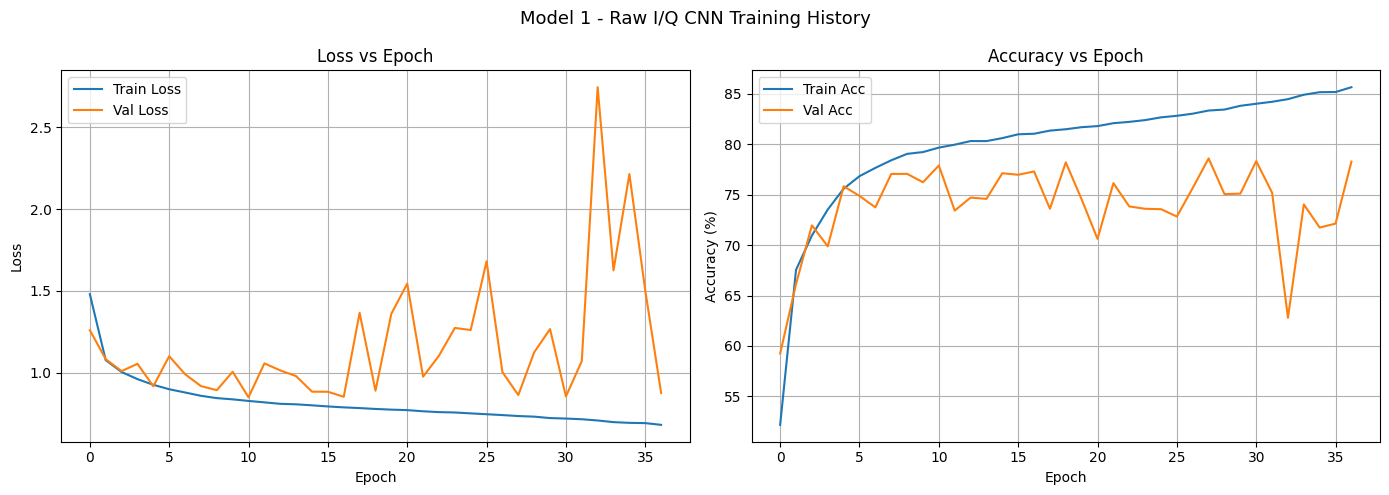

In [ ]:
# Cell 11 - Plot Training History

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses,   label="Val Loss")
ax1.set_title("Loss vs Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

# Accuracy curves
ax2.plot([a*100 for a in train_accs], label="Train Acc")
ax2.plot([a*100 for a in val_accs],   label="Val Acc")
ax2.set_title("Accuracy vs Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.suptitle("Model 1 - Raw I/Q CNN Training History", fontsize=13)
plt.tight_layout()
plt.show()

# statistical scores you can go.

for evaluation, make sure to use macro f1 instead of f1 - because some modulation types have worse classification ability at the same low snr compared to others type shi

In [ ]:
all_preds = []
all_labels = []
all_snrs = []
all_conf = []
all_true_prob = []
all_entropy = []
all_probs = []

model.eval()
with torch.no_grad():
    for inputs, labels_batch, snrs_batch in test_loader:
        inputs = inputs.to(device)
        labels_dev = labels_batch.to(device)

        outputs = model(inputs)
        probs = torch.softmax(outputs, dim = 1)

        preds = probs.argmax(dim = 1)
        conf = probs.max(dim = 1).values
        true_prob = probs[torch.arange(probs.shape[0]), labels_dev]
        entropy = -(probs * torch.log(probs + 1e-12)).sum(dim = 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels_batch.numpy())
        all_snrs.extend(snrs_batch.numpy())
        all_conf.extend(conf.cpu().numpy())
        all_true_prob.extend(true_prob.cpu().numpy())
        all_entropy.extend(entropy.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_snrs = np.array(all_snrs)
all_conf = np.array(all_conf)
all_true_prob = np.array(all_true_prob)
all_entropy = np.array(all_entropy)
all_probs = np.concatenate(all_probs, axis = 0)

print("Done. Test samples:", len(all_preds))

Done. Test samples: 51917


In [ ]:
# rebuilding the metrics that the new eval loop no longer computes
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

overall_acc = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average = 'macro')

print(f"Overall Accuracy: {overall_acc*100:.2f}%")
print(f"F1 Score (the macro one) : {macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names = MOD_LABELS, digits = 3))

snr_range = sorted(np.unique(all_snrs).tolist())
snr_accs = {}

for snr in snr_range:
    mask = all_snrs == snr
    snr_acc = accuracy_score(all_labels[mask], all_preds[mask])
    snr_accs[snr] = snr_acc
    print(f"SNR {snr:4d} dB | Acc: {snr_acc*100:.2f}%")

Overall Accuracy: 78.59%
F1 Score (the macro one) : 0.7847

Classification Report:
              precision    recall  f1-score   support

        BPSK      0.861     0.769     0.812      3994
        QPSK      0.821     0.636     0.716      3993
        8PSK      0.900     0.645     0.752      3988
       16QAM      0.749     0.487     0.590      3994
       64QAM      0.637     0.724     0.678      3996
        PAM4      0.559     0.884     0.685      3992
        GFSK      0.830     0.901     0.864      3994
       CPFSK      0.919     0.727     0.812      3995
        2FSK      0.855     0.954     0.902      3996
        4FSK      0.828     0.729     0.775      3994
        B-FM      0.660     0.869     0.750      3992
      AM-DSB      0.905     0.977     0.940      3998
      AM-SSB      0.936     0.913     0.924      3991

    accuracy                          0.786     51917
   macro avg      0.805     0.786     0.785     51917
weighted avg      0.805     0.786     0.785     519

In [ ]:
correct = (all_preds == all_labels)

print(f"Mean confidence (all)     : {all_conf.mean():.3f}")
print(f"Mean confidence (correct) : {all_conf[correct].mean():.3f}")
print(f"Mean confidence (wrong)   : {all_conf[~correct].mean():.3f}")
print(f"Mean prob on true class   : {all_true_prob.mean():.3f}")
print(f"Mean entropy              : {all_entropy.mean():.3f}")
print(f"  ln(6)  = {np.log(6):.3f}  (uncertain across 6 classes)")
print(f"  ln(13) = {np.log(13):.3f}  (no idea at all)")

Mean confidence (all)     : 0.800
Mean confidence (correct) : 0.909
Mean confidence (wrong)   : 0.400
Mean prob on true class   : 0.739
Mean entropy              : 0.666
  ln(6)  = 1.792  (uncertain across 6 classes)
  ln(13) = 2.565  (no idea at all)


In [ ]:
high = (all_snrs >= 20)

print("High SNR only (>= 20 dB)")
print("Class      Acc      Conf    TrueP   Entropy")
for i in range(13):
    mask = (all_labels == i) & high
    acc_i = (all_preds[mask] == all_labels[mask]).mean()
    conf_i = all_conf[mask].mean()
    true_i = all_true_prob[mask].mean()
    ent_i = all_entropy[mask].mean()
    print(f"{MOD_LABELS[i]:8s} {acc_i*100:6.2f}%   {conf_i:.3f}   {true_i:.3f}   {ent_i:.3f}")

High SNR only (>= 20 dB)
Class      Acc      Conf    TrueP   Entropy
BPSK     100.00%   0.965   0.965   0.230
QPSK      99.35%   0.948   0.945   0.303
8PSK      98.48%   0.954   0.949   0.245
16QAM     84.78%   0.909   0.815   0.376
64QAM     99.46%   0.961   0.960   0.213
PAM4     100.00%   0.983   0.983   0.119
GFSK     100.00%   0.964   0.964   0.240
CPFSK    100.00%   0.958   0.958   0.268
2FSK     100.00%   0.968   0.968   0.215
4FSK     100.00%   0.962   0.962   0.248
B-FM     100.00%   0.961   0.961   0.255
AM-DSB    99.78%   0.964   0.964   0.233
AM-SSB    99.67%   0.950   0.950   0.307


In [ ]:
for snr in sorted(np.unique(all_snrs)):
    mask = (all_snrs == snr)
    acc_s = (all_preds[mask] == all_labels[mask]).mean()
    conf_s = all_conf[mask].mean()
    ent_s = all_entropy[mask].mean()
    print(f"SNR {snr:4d} dB | Acc: {acc_s*100:5.2f}% | Conf: {conf_s:.3f} | Entropy: {ent_s:.3f}")

SNR  -20 dB | Acc: 20.08% | Conf: 0.240 | Entropy: 2.150
SNR  -18 dB | Acc: 26.89% | Conf: 0.285 | Entropy: 2.035
SNR  -16 dB | Acc: 31.61% | Conf: 0.361 | Entropy: 1.833
SNR  -14 dB | Acc: 36.40% | Conf: 0.472 | Entropy: 1.560
SNR  -12 dB | Acc: 39.70% | Conf: 0.583 | Entropy: 1.261
SNR  -10 dB | Acc: 46.72% | Conf: 0.662 | Entropy: 1.036
SNR   -8 dB | Acc: 55.98% | Conf: 0.711 | Entropy: 0.878
SNR   -6 dB | Acc: 66.97% | Conf: 0.747 | Entropy: 0.767
SNR   -4 dB | Acc: 78.21% | Conf: 0.793 | Entropy: 0.659
SNR   -2 dB | Acc: 85.73% | Conf: 0.845 | Entropy: 0.544
SNR    0 dB | Acc: 89.87% | Conf: 0.876 | Entropy: 0.467
SNR    2 dB | Acc: 92.69% | Conf: 0.903 | Entropy: 0.406
SNR    4 dB | Acc: 95.64% | Conf: 0.922 | Entropy: 0.352
SNR    6 dB | Acc: 95.99% | Conf: 0.936 | Entropy: 0.313
SNR    8 dB | Acc: 97.90% | Conf: 0.947 | Entropy: 0.276
SNR   10 dB | Acc: 98.05% | Conf: 0.953 | Entropy: 0.261
SNR   12 dB | Acc: 98.10% | Conf: 0.954 | Entropy: 0.257
SNR   14 dB | Acc: 98.00% | Con

In [ ]:
bin_edges = [0.0, 0.2, 0.4, 0.6, 0.8, 1.01]

print("Conf range    n       Accuracy   Mean conf")
for b in range(5):
    lo = bin_edges[b]
    hi = bin_edges[b + 1]
    mask = (all_conf >= lo) & (all_conf < hi)
    n = mask.sum()
    if n > 0:
        print(f"{lo:.1f} - {hi:.1f}   {n:6d}   {correct[mask].mean()*100:6.2f}%    {all_conf[mask].mean():.3f}")

Conf range    n       Accuracy   Mean conf
0.0 - 0.2     3654    12.15%    0.145
0.2 - 0.4     4029    21.25%    0.292
0.4 - 0.6     3601    39.71%    0.500
0.6 - 0.8     3476    57.80%    0.703
0.8 - 1.0    37157    97.05%    0.958


CONFUSION OF THE MATRIX BECAUSE THE MATRIX IS CONFUSING

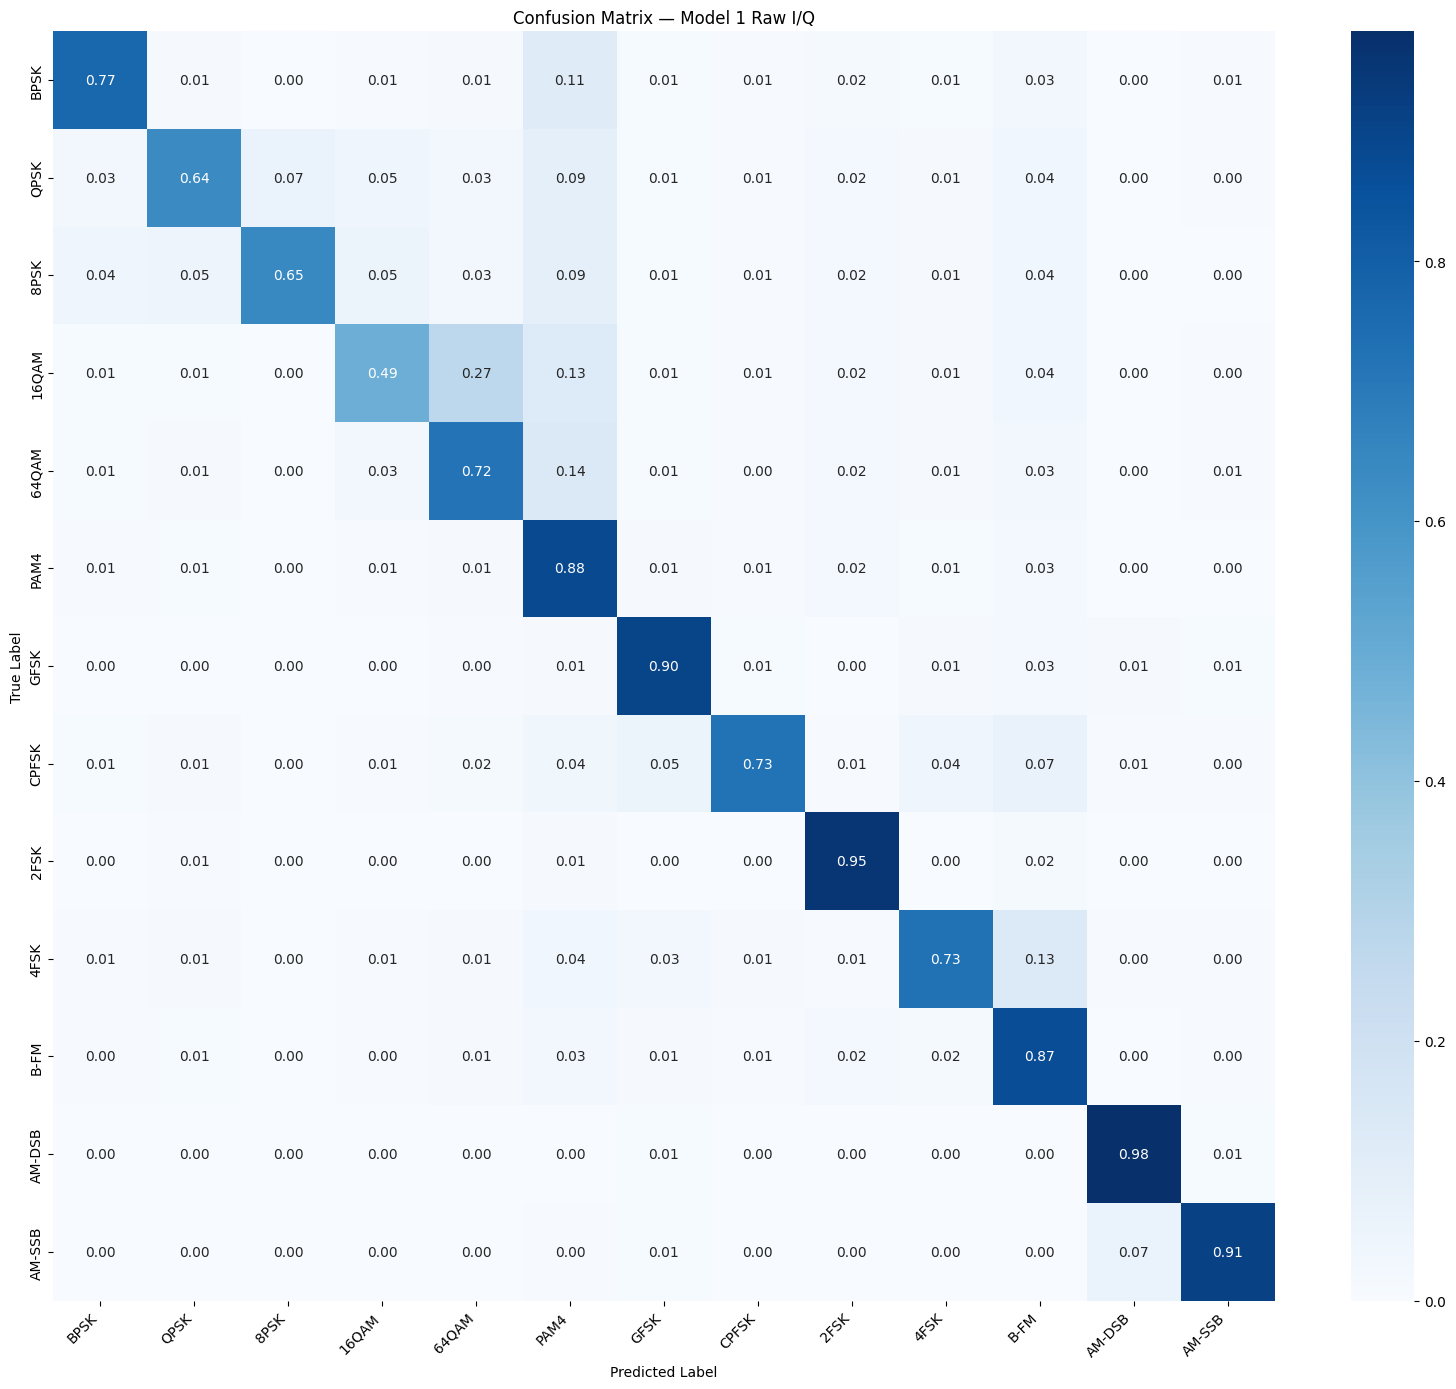

In [ ]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(16, 14))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=MOD_LABELS, yticklabels=MOD_LABELS)
plt.title("Confusion Matrix — Model 1 Raw I/Q")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

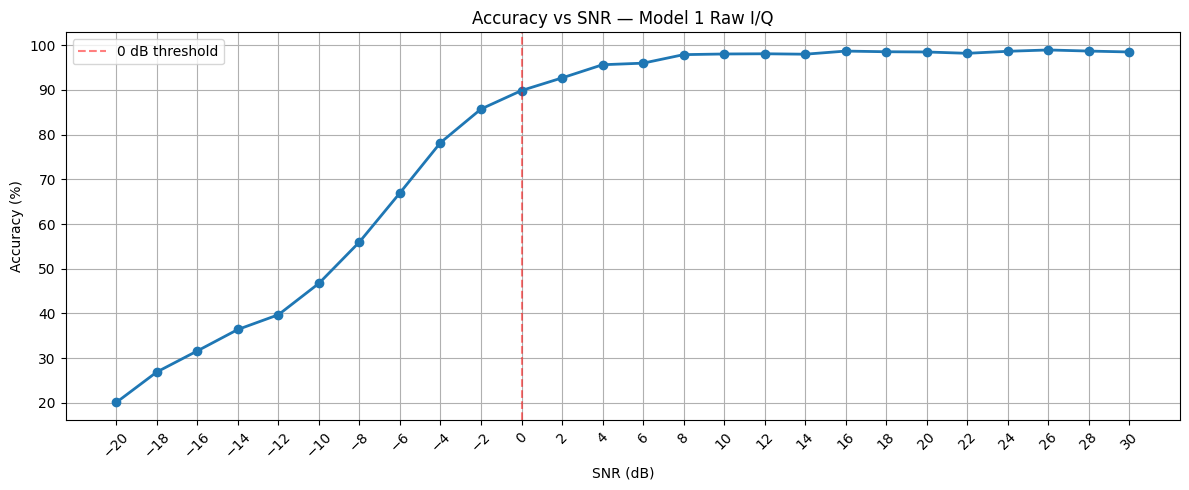

In [ ]:
# Accuracy vs SNR Plot

# x = snr and y is acc -> depend and independent stuff

snrs_sorted = sorted(snr_accs.keys())
accs = [snr_accs[s]*100 for s in snrs_sorted]

plt.figure(figsize=(12, 5))
plt.plot(snrs_sorted, accs, marker='o', linewidth=2)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='0 dB threshold')
plt.title("Accuracy vs SNR — Model 1 Raw I/Q")
plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.xticks(snrs_sorted, rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
np.savez(os.path.join(save_dir, "iq_v2_8192_eval.npz"),
         preds = all_preds,
         labels = all_labels,
         snrs = all_snrs,
         conf = all_conf,
         true_prob = all_true_prob,
         entropy = all_entropy,
         probs = all_probs)

print("Saved.", all_probs.shape)

Saved. (51917, 13)
